Universidad Torcuato Di Tella

Licenciatura en Tecnología Digital

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**

# **Trabajo Práctico — Ejercicio N°8: Mínimos cuadrados mediante métodos iterativos**

Resolvemos todas las importaciones necesarias para el correcto funcionamiento del código.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [20]:
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

In [21]:
n = 8
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]
A7 = matriz_proyeccion(n, D7)[0]

X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

In [22]:
seed = 73
z = np.random.normal(loc=0.0, scale=1.0, size=119)

b7 = A7 @ x_fantoma
escala = np.sqrt(np.mean(b7**2))

ruido = 0.06 * escala * z
b_sigma = b7 + ruido

1. Interpretar las expresiones provistas e implementar funciones que calculen $E(x)$ y $\nabla E(x)$. Construir también $H$ y verificar numéricamente que es simétrica.

In [23]:
# Construcción de E(X)
def E(x, bs):
    b_real = A7@x
    # b_sigma = b_real + ruidos[3]
    return 0.5*(np.linalg.norm(b_real - bs)**2)

# Construcción del gradiente de E(X)
def E_gradient(x, bs):
    b_real = A7@x
    # b_sigma = b_real + ruidos[3]
    return A7.transpose() @ (b_real - bs)

# Función que verifica simetría
def is_simetrical(A:np.ndarray)->bool:
    if np.array_equal(A.transpose(), A): return True
    return False
 
A7 = np.array(A7)

# Construcción de la matriz hessiana y verificación de simetría
matriz_hessiana = A7.transpose() @ A7
print("Es simetrica la matriz? ->", is_simetrical(matriz_hessiana))

Es simetrica la matriz? -> True


De las fórmulas provistas, se intepreta lo siguiente:

- $E(x)\rightarrow$ es la función objetivo a minimizar. Funciona como una métrica que nos indica qué tan cerca está nuestra reconstrucción de la solución real.
- $\nabla E(x)\rightarrow$ es el gradiente de la función objetivo, o bien, el conjunto de todas las primeras derivadas parciales.
- $H_f(x)\rightarrow$ es la matriz hessiana que contiene todas las segundas derivadas parciales de la función objetivo.

Estos lo usaremos para hacer el descenso del gradiente respecto a la distancia entre nuestra solución parcial y la mejor aproximación factible, es decir, aquella para la cual $E(\hat{x}) = \frac{1}{2}||A_7\hat{x} - b_\sigma||² = \frac{1}{2}||b_7 - b_\sigma||² = \frac{1}{2}||r_\sigma||²$.


2. Implementar gradiente descendiente mediante $x_{t+1} = x_t − \alpha \nabla E(x_t)$, comenzando con $x_0 = 0$. Registrar el costo y la norma del gradiente durante las iteraciones.

In [24]:
def gradiente_descendente(x_0, bs, alpha = 0.01, tolerancia = 0.0001, max_iter = 1000, verbose=False):
    
    x_t   = x_0

    # Definimos un historial para el valor del costo y la norma del gradiente
    cost_log = list()
    grad_norm_log = list()

    iter  = 0

    while iter <= max_iter:
        # Computamos siguiente x a partir de la derivada de la función
        x_tsig = x_t - alpha * E_gradient(x_t,bs)

        # Actualizamos los historiales e imprimimos por pantalla
        cost_log.append(E(x_t,bs))
        grad_norm_log.append(np.linalg.norm(E_gradient(x_t,bs)))
        if verbose: print("Iteración", iter, "-> Mínimo hallado hasta ahora: ", E(x_t,bs), "-- Norma del gradiente: ", np.linalg.norm(E_gradient(x_t,bs)))

        # Chequeamos si ya alcanzamos la convergencia
        if abs(E(x_tsig,bs) - E(x_t,bs)) < tolerancia:
          break

        # Preparamos la siguiente iteración
        x_t = x_tsig
        iter = iter + 1

    return np.array(x_tsig), cost_log, grad_norm_log

A continuación, utilizamos las mediciones $b_\sigma$ obtenidas de aplicar ruido sobre $b_7 = A_7 x_{fantoma}$ para evaluar el desempeño del método del gradiente. Asimismo, fijamos los parámetros del modelo.

In [25]:
ALPHA = 0.05
MAX_ITER = 1000
TOLERANCIA = 0.0001

res_gd = gradiente_descendente(x_0=np.zeros((64)), bs=b_sigma, alpha=ALPHA, tolerancia=TOLERANCIA, max_iter=MAX_ITER, verbose=True)
x_gd = res_gd[0]
costos = res_gd[1]
grad_norms = res_gd[2]

Iteración 0 -> Mínimo hallado hasta ahora:  71.7733159309029 -- Norma del gradiente:  66.9470944777682
Iteración 1 -> Mínimo hallado hasta ahora:  43.17255303815 -- Norma del gradiente:  53.972706181830915
Iteración 2 -> Mínimo hallado hasta ahora:  28.114889249390394 -- Norma del gradiente:  44.176434166584755
Iteración 3 -> Mínimo hallado hasta ahora:  18.748406642921708 -- Norma del gradiente:  36.28397289667346
Iteración 4 -> Mínimo hallado hasta ahora:  12.629161142481987 -- Norma del gradiente:  29.836986925706924
Iteración 5 -> Mínimo hallado hasta ahora:  8.55577269863087 -- Norma del gradiente:  24.547866848067418
Iteración 6 -> Mínimo hallado hasta ahora:  5.821273452562884 -- Norma del gradiente:  20.20130523006811
Iteración 7 -> Mínimo hallado hasta ahora:  3.9776877577022676 -- Norma del gradiente:  16.626612699970018
Iteración 8 -> Mínimo hallado hasta ahora:  2.7317237355687127 -- Norma del gradiente:  13.68561583293413
Iteración 9 -> Mínimo hallado hasta ahora:  1.88834

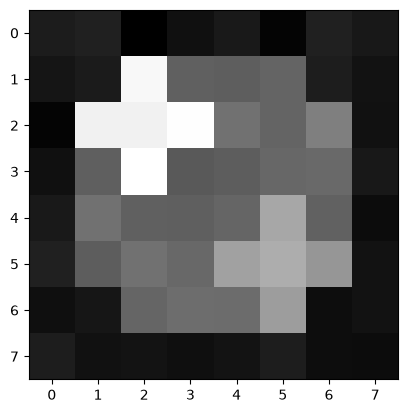

In [26]:
# Graficamos la reconstrucción obtenida mediante este método
X_gd = x_gd.reshape(8,8)
plt.imshow(X_gd, cmap='gray')

3. Calcular el mayor autovalor $\mu _{max}$ de $H$ y probar tasas de aprendizaje dentro y fuera del intervalo $0 < \alpha < 2/ \mu _{max}$. Comparar las curvas del costo y describir cuándo el método converge o se vuelve inestable.

In [27]:
# Buscamos el máximo autovalor
umax = np.max(np.linalg.eig(matriz_hessiana).eigenvalues)
print("umax: ", umax, "-- 2/umax:", 2/umax)


umax:  (36.46340500801554+0j) -- 2/umax: (0.05484951280771369+0j)


Primero, vamos a observar qué sucede para tasas de aprendizaje contenidas en el intervalo. Al mismo tiempo, vamos a ir guardando la evolución de los costos y de la norma del gradiente para cada tasa de aprendizaje evaluada.

In [28]:
curvas_de_costo = list()
curvas_grad_norm = list()

In [29]:
for alpha in [0.01, 0.02, 0.03, 0.04, 0.05, 0.054]:
    res_gd = gradiente_descendente(x_0=np.zeros((64)), bs=b_sigma, alpha=alpha, tolerancia=TOLERANCIA, max_iter=MAX_ITER)
    x_gd = res_gd[0]
    curvas_de_costo.append(res_gd[1])
    curvas_grad_norm.append(res_gd[2])
    print("Para alpha =", alpha, "el mínimo alcanzado es", E(x_gd, b_sigma))

Para alpha = 0.01 el mínimo alcanzado es 0.10035055880652262
Para alpha = 0.02 el mínimo alcanzado es 0.09739233515978746
Para alpha = 0.03 el mínimo alcanzado es 0.09624727220848603
Para alpha = 0.04 el mínimo alcanzado es 0.09560794234194112
Para alpha = 0.05 el mínimo alcanzado es 0.09520410173871965
Para alpha = 0.054 el mínimo alcanzado es 0.09507764782482304


A simple vista, se puede ver que, cuanto más nos acercamos al límite del intervalo, mejores son los resultados obtenidos. Pareciera que las primeras tasas resultan demasiado lentas y convergen muy despacio.

Veamos qué ocurre si nos salimos del intervalo.

In [30]:
# Alpha = 0.055
res_gd = gradiente_descendente(x_0=np.zeros((64)), bs=b_sigma, alpha=0.055, tolerancia=TOLERANCIA, max_iter=MAX_ITER)
x_gd = res_gd[0]
curvas_de_costo.append(res_gd[1])
curvas_grad_norm.append(res_gd[2])
print("Para alpha =", 0.055, "el mínimo alcanzado es", E(x_gd, b_sigma))

# Alpha = 0.06
res_gd = gradiente_descendente(x_0=np.zeros((64)), bs=b_sigma, alpha=0.06, tolerancia=TOLERANCIA, max_iter=MAX_ITER)
x_gd = res_gd[0]
curvas_de_costo.append(res_gd[1])
curvas_grad_norm.append(res_gd[2])
print("Para alpha =", 0.06, "el mínimo alcanzado es", E(x_gd, b_sigma))

Para alpha = 0.055 el mínimo alcanzado es 3302520.4355202243
Para alpha = 0.06 el mínimo alcanzado es 2.5131067117177314e+151


Incluso si nos pasamos por muy poco del límite, el mínimo obtenido se dispara por los aires, y el método se vuelve inestable.

Gráficamente, esto se puede observar en la forma de las curvas de costo y las curvas de la norma del gradiente. Para las últimas dos tasas evaluadas, $0.055$ y $0.06$, las curvas empiezan a crecer desmesuradamente en lugar de bajar, que es lo que debería suceder si lograran converger al mínimo.

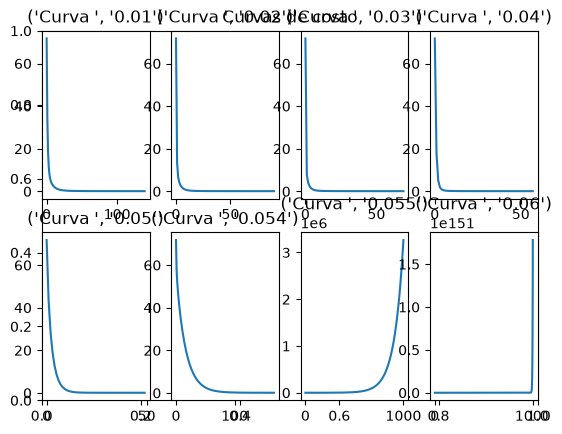

In [31]:
plt.title("Curvas de costo")

alphas = [0.01, 0.02, 0.03, 0.04, 0.05, 0.054, 0.055, 0.06]
for i in range(len(curvas_de_costo)):
    plt.subplot(2, 4, i+1)
    plt.plot(curvas_de_costo[i])
    plt.title(('Curva ', str(alphas[i])))
    # plt.ylabel('Costo')
    # plt.xlabel('Iteraciones de gradiente descendente')

plt.show()

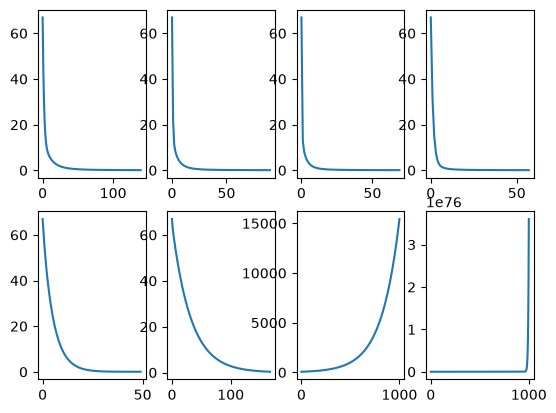

In [32]:
for i in range(len(curvas_grad_norm)):
    plt.subplot(2, 4, i+1)
    plt.plot(curvas_grad_norm[i])
    # plt.title('Curva')
    # plt.ylabel('Costo')
    # plt.xlabel('Iteraciones de gradiente descendente')

plt.show()

4. Implementar el método de Newton resolviendo $H\text{p}_t = \nabla E(x_t)$ mediante `np.linalg.solve` y actualizando $x_{t+1} = x_t − \text{p}_t$. Verificar que alcanza la solución en una sola iteración y explicar por qué esto ocurre para una función cuadrática con Hessiana constante.

In [33]:
def metodo_newton(x_0, bs, tolerancia = 0.0001, max_iter = 1000, verbose=False):
    x_t   = x_0
    iter  = 0

    while iter <= max_iter:
        if verbose: print("Iteración: ", iter, "- Mínimo alcanzado hasta el momento: ", E(x_t,bs))

        x_tsig = x_t - np.linalg.solve(a=matriz_hessiana, b=E_gradient(x_t,bs))

        # Chequeamos si ya alcanzamos la convergencia
        if abs(E(x_tsig,bs) - E(x_t,bs)) < tolerancia:
          break

        # Preparamos la siguiente iteración
        x_t = x_tsig
        iter = iter + 1

    return np.array(x_tsig)

In [34]:
x_newton = metodo_newton(x_0=np.zeros((64)), bs=b_sigma, verbose=True)

Iteración:  0 - Mínimo alcanzado hasta el momento:  71.7733159309029
Iteración:  1 - Mínimo alcanzado hasta el momento:  0.09359978042709866


5. Comparar las reconstrucciones obtenidas mediante gradiente descendiente, Newton y `lstsq`.

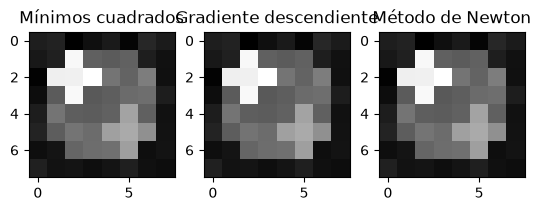

E(X) con mínimos cuadrados: 0.09359978042709866
E(X) con mínimos cuadrados: 0.09507764782482304
E(X) con mínimos cuadrados: 0.09359978042709861


In [35]:
ALPHA = 0.054
TOLERANCIA = 0.0001
MAX_ITER = 1000

x_lstsq = np.linalg.lstsq(a=A7, b=b_sigma)[0]
x_gd = gradiente_descendente(x_0=np.zeros((64)), bs=b_sigma, alpha=ALPHA, tolerancia=TOLERANCIA, max_iter=MAX_ITER)[0]

X_lstsq = x_lstsq.reshape(8,8)
X_gd = x_gd.reshape(8,8)
X_newton = x_newton.reshape(8,8)

plt.subplot(1, 3, 1)
plt.title('Mínimos cuadrados')
plt.imshow(X_lstsq, cmap='gray')    

plt.subplot(1, 3, 2)
plt.title('Gradiente descendiente')
plt.imshow(X_gd, cmap='gray') 

plt.subplot(1, 3, 3)
plt.title('Método de Newton')
plt.imshow(X_newton, cmap='gray') 

plt.show()

print("E(X) con mínimos cuadrados:", E(x_lstsq, b_sigma))
print("E(X) con mínimos cuadrados:", E(x_gd, b_sigma))
print("E(X) con mínimos cuadrados:", E(x_newton, b_sigma))

Si bien la visualización de las reconstrucciones podría sugerir resultados iguales para los tres métodos, al analizar la función objetivo es evidente que tanto la solución por mínimos cuadrados como la solución por método de Newton llegan a la mejor aproximación. El método del gradiente también llega a una aproximación muy buena con la tasa de aprendizaje correcta.